In [7]:
import numpy as np
import matplotlib.pyplot as plt
from process_raw_beams import Beam_Processing

import utils
import copy
import pandas as pd
from pathlib import Path


In [2]:
beam_proc = Beam_Processing(dirpath="/mnt/data/POLOCALC/lab/WR10/antenna/ANT_001/radiation_pattern",
                            date="20251021"
                           )

2026-08-07 12:44:53 - stout - WARNING - [authenticated_user] - Cannot write to log directory /mnt/data/POLOCALC/logs: [Errno 13] Permission denied: '/mnt/data/POLOCALC/logs/stout.log'. Using console logging only.
2026-08-07 12:44:53 - stout - INFO - [authenticated_user] - Centralized logging system initialized


In [3]:
beam_proc.save_processed_data()

Gain computed from Hplane and Eplane

FWHM processed data saved to: /mnt/data/POLOCALC/lab/WR10/antenna/ANT_001/radiation_pattern/20251021_fwhm_processed.hdf5

Gain processed data saved to: /mnt/data/POLOCALC/lab/WR10/antenna/ANT_001/radiation_pattern/20251021_gain_processed.csv


In [12]:
utils.load_data(Path("/mnt/data/POLOCALC/lab/WR10/antenna/ANT_001/radiation_pattern/20251021_fwhm_processed.hdf5"))

{'Dplane': {'FWHM [deg]': array([36.57156465, 37.88163479, 38.76040254, 38.42402518, 37.46931802,
         35.53614919, 34.4585101 , 35.53932878, 35.73661491, 35.31429909,
         34.19045326, 32.75579103, 33.26327682, 33.92455813, 33.69032195,
         32.5765816 , 31.29681612, 31.32560993, 31.94700306, 31.84216411,
         31.06828905, 30.13540933, 30.08354158, 30.43471894, 30.19983685,
         29.51262396, 28.76884148, 28.80379809, 29.06358452, 28.85096609,
         28.17704408, 27.76615934, 27.81617198, 27.81111878, 27.40510053,
         26.77298369]),
  'Frequency [GHz]': array([ 75.,  76.,  77.,  78.,  79.,  80.,  81.,  82.,  83.,  84.,  85.,
          86.,  87.,  88.,  89.,  90.,  91.,  92.,  93.,  94.,  95.,  96.,
          97.,  98.,  99., 100., 101., 102., 103., 104., 105., 106., 107.,
         108., 109., 110.]),
  'err FWHM [deg]': array([0.00584873, 0.00565433, 0.00471086, 0.0044856 , 0.00458295,
         0.00533542, 0.00497169, 0.00453325, 0.00548504, 0.00602414,
     

In [9]:
Path("/mnt/data/POLOCALC/lab/WR10/antenna/ANT_001/radiation_pattern/20251021_fwhm_processed.hdf5")

PosixPath('/mnt/data/POLOCALC/lab/WR10/antenna/ANT_001/radiation_pattern/20251021_fwhm_processed.hdf5')

In [12]:
fwhm_df_pd = pd.DataFrame(beam_proc.fwhm_df)
fwhm_df_pd.to_csv(in)

In [10]:
beam_proc.fwhm_df["Dplane"].keys()

dict_keys(['75.0 GHz', '76.0 GHz', '77.0 GHz', '78.0 GHz', '79.0 GHz', '80.0 GHz', '81.0 GHz', '82.0 GHz', '83.0 GHz', '84.0 GHz', '85.0 GHz', '86.0 GHz', '87.0 GHz', '88.0 GHz', '89.0 GHz', '90.0 GHz', '91.0 GHz', '92.0 GHz', '93.0 GHz', '94.0 GHz', '95.0 GHz', '96.0 GHz', '97.0 GHz', '98.0 GHz', '99.0 GHz', '100.0 GHz', '101.0 GHz', '102.0 GHz', '103.0 GHz', '104.0 GHz', '105.0 GHz', '106.0 GHz', '107.0 GHz', '108.0 GHz', '109.0 GHz', '110.0 GHz'])

In [15]:
freq_H, fwhm_H, err_fwhm_H = utils.extract_fwhm_from_dict(beam_proc.fwhm_df,plane="Hplane")
freq_E, fwhm_E, err_fwhm_E = utils.extract_fwhm_from_dict(beam_proc.fwhm_df,plane="Eplane")

wrong_freq_H = copy.copy(freq_H)
wrong_freq_H[2]=0

In [22]:
np.all(freq_E==wrong_freq_H) == True

np.False_

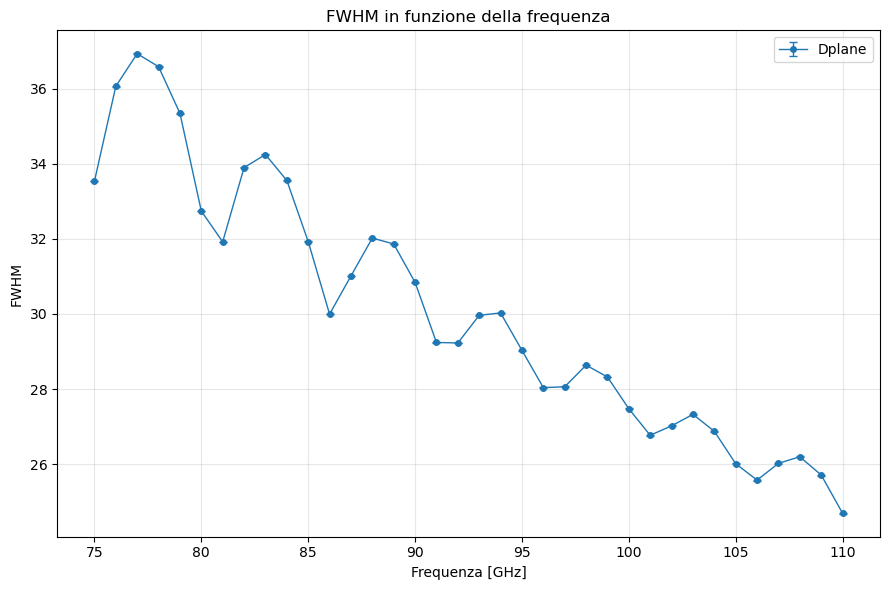

In [8]:
d = beam_proc.fwhm_df['Eplane']

freqs = []
fwhm = []
err_fwhm = []

for key, val in d.items():
    freq = float(key.replace(' GHz', ''))
    freqs.append(freq)
    fwhm.append(val['fwhm'])
    err_fwhm.append(val['err_fwhm'])

# Ordina per frequenza (per sicurezza, se il dizionario non fosse già ordinato)
freqs, fwhm, err_fwhm = zip(*sorted(zip(freqs, fwhm, err_fwhm)))

# Plot
plt.figure(figsize=(9, 6))
plt.errorbar(freqs, fwhm, yerr=err_fwhm, fmt='o-', capsize=3, 
             markersize=4, linewidth=1, elinewidth=1, label='Dplane')

plt.xlabel('Frequenza [GHz]')
plt.ylabel('FWHM')
plt.title('FWHM in funzione della frequenza')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [3]:
single_freq_beam = beam_proc.get_single_freq_beam(freq=93,plane="Hplane")

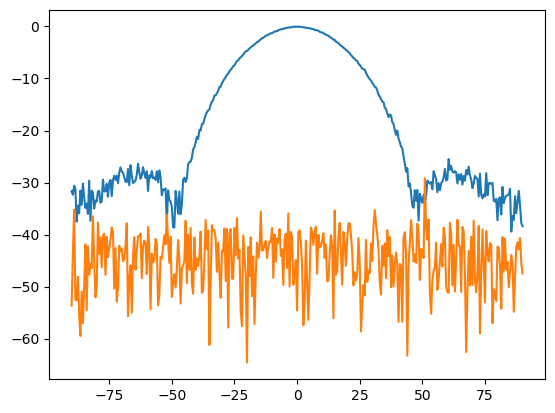

In [4]:
plt.plot(single_freq_beam["Hplane"]["copol"]["Ang(DEG)"],single_freq_beam["Hplane"]["copol"]["S12(DB)"])
plt.plot(single_freq_beam["Hplane"]["crosspol"]["Ang(DEG)"],single_freq_beam["Hplane"]["crosspol"]["S12(DB)"])


In [7]:
beam_proc.get_fwhm(n_fwhm=1)

Dplane

75.0 GHz 

[-33.5 -33.  -32.5 -32.  -31.5 -31.  -30.5 -30.  -29.5 -29.  -28.5 -28.
 -27.5 -27.  -26.5 -26.  -25.5 -25.  -24.5 -24.  -23.5 -23.  -22.5 -22.
 -21.5 -21.  -20.5 -20.  -19.5 -19.  -18.5 -18.  -17.5 -17.  -16.5 -16.
 -15.5 -15.  -14.5 -14.  -13.5 -13.  -12.5 -12.  -11.5 -11.  -10.5 -10.
  -9.5  -9.   -8.5  -8.   -7.5  -7.   -6.5  -6.   -5.5  -5.   -4.5  -4.
  -3.5  -3.   -2.5  -2.   -1.5  -1.   -0.5  -0.    0.5   1.    1.5   2.
   2.5   3.    3.5   4.    4.5   5.    5.5   6.    6.5   7.    7.5   8.
   8.5   9.    9.5  10.   10.5  11.   11.5  12.   12.5  13.   13.5  14.
  14.5  15.   15.5  16.   16.5  17.   17.5  18.   18.5  19.   19.5  20.
  20.5  21.   21.5  22.   22.5  23.   23.5  24.   24.5  25.   25.5  26.
  26.5  27.   27.5  28.   28.5  29.   29.5  30.   30.5  31.   31.5  32.
  32.5  33.   33.5]
76.0 GHz 

[-33.5 -33.  -32.5 -32.  -31.5 -31.  -30.5 -30.  -29.5 -29.  -28.5 -28.
 -27.5 -27.  -26.5 -26.  -25.5 -25.  -24.5 -24.  -23.5 -23.  -22.5 -22.
 -21.5 -21.  -